# Projet Deep Learning : expressions faciales
TERRAK Adam, Ing3 IA

## Partie 1 : données

### Dataset
RAF-DB (Real-world Affective Faces Database), créé par Shan Li, Weihong Deng et Junping Du (CVPR 2017). J'utilise la copie au format parquet publiée sur Hugging Face : https://huggingface.co/datasets/elipaluma/RAF-DB_Kaggle
Licence : usage de recherche non commercial (conditions des auteurs de RAF-DB), la copie Hugging Face n'indique pas de licence.

Je l'ai choisi parce qu'il a les 7 classes du sujet et des images en couleur de visages pris dans des conditions réelles. Elles sont petites (100x100), donc l'entraînement reste rapide.

In [9]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from huggingface_hub import hf_hub_download

np.random.seed(42)

In [10]:
repo = "elipaluma/RAF-DB_Kaggle"
train_df = pd.read_parquet(hf_hub_download(repo, "data/train-00000-of-00001.parquet", repo_type="dataset"))
test_df = pd.read_parquet(hf_hub_download(repo, "data/test-00000-of-00001.parquet", repo_type="dataset"))

### Chargement
Les données sont dans deux fichiers parquet, train et test. Chaque ligne contient une image JPEG et son label, de 1 à 7. Je décode les images dans des tableaux NumPy, comme MNIST et FER-2013 : x contient les images (les données d'entrée) et y les labels. Je retire 1 aux labels pour qu'ils aillent de 0 à 6. Les noms des classes viennent de la documentation de RAF-DB : 1 surprise, 2 fear, 3 disgust, 4 happy, 5 sad, 6 angry, 7 neutral.

In [11]:
classes = ["surprise", "fear", "disgust", "happy", "sad", "angry", "neutral"]

def load(df):
    x = np.array([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]])
    y = df["label"].values - 1
    return x, y

x_train, y_train = load(train_df)
x_test, y_test = load(test_df)

### Description

In [12]:
print("x_train:", x_train.shape, x_train.dtype)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)
print("total images:", len(x_train) + len(x_test))
print("classes:", classes)
print("pixels min/max:", x_train.min(), x_train.max())

im = Image.open(io.BytesIO(train_df["image"][0]["bytes"]))
print(im.format, im.mode, im.size)

x_train: (12271, 100, 100, 3) uint8
y_train: (12271,)
x_test: (3068, 100, 100, 3)
y_test: (3068,)
total images: 15339
classes: ['surprise', 'fear', 'disgust', 'happy', 'sad', 'angry', 'neutral']
pixels min/max: 0 255
JPEG RGB (100, 100)


- 15 339 images au total (12 271 en train, 3 068 en test)
- 7 classes : surprise, peur, dégoût, joie, tristesse, colère, neutre
- images de 100x100 pixels
- fichiers JPEG en couleur (3 canaux RVB), pixels de 0 à 255

surprise 1290 329
fear 281 74
disgust 717 160
happy 4772 1185
sad 1982 478
angry 705 162
neutral 2524 680
max/min ratio: 16.98220640569395


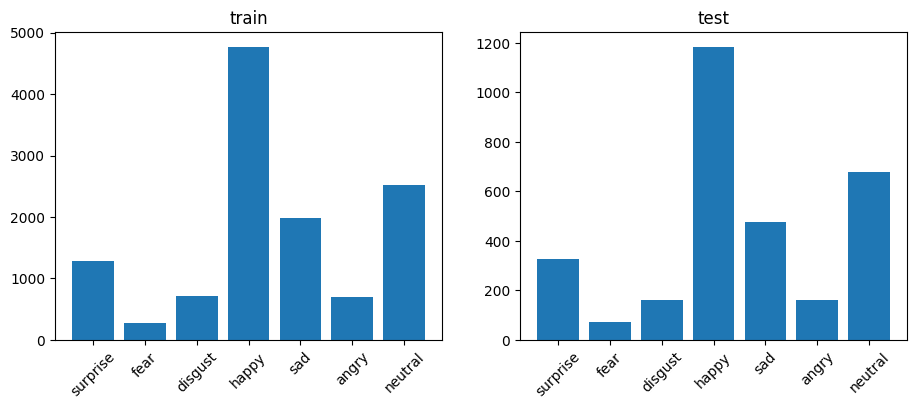

In [13]:
train_counts = np.bincount(y_train)
test_counts = np.bincount(y_test)

for i, c in enumerate(classes):
    print(c, train_counts[i], test_counts[i])
print("max/min ratio:", train_counts.max() / train_counts.min())

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.bar(classes, train_counts)
plt.xticks(rotation=45)
plt.title("train")
plt.subplot(1, 2, 2)
plt.bar(classes, test_counts)
plt.xticks(rotation=45)
plt.title("test")
plt.show()

Joie a 4 772 images contre 281 pour peur, soit environ 17 fois plus. Le déséquilibre est fort : les petites classes seront probablement moins bien apprises, et l'accuracy seule ne suffira pas pour les évaluer.

### Exemples par classe

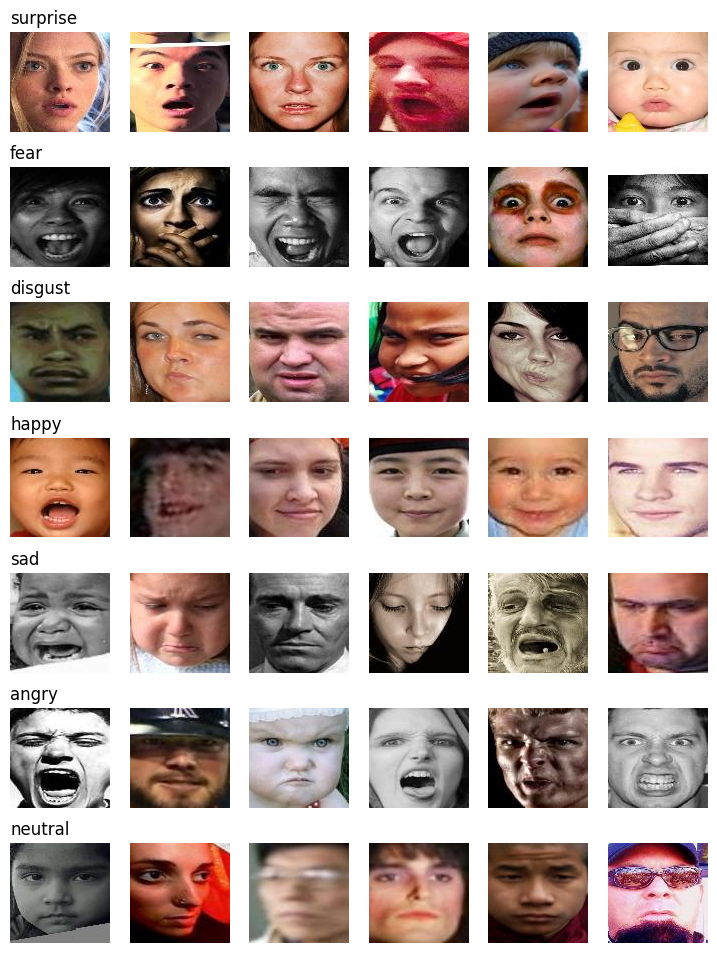

In [14]:
plt.figure(figsize=(9, 12))
for i, c in enumerate(classes):
    idx = np.random.choice(np.where(y_train == i)[0], 6, replace=False)
    for j, k in enumerate(idx):
        plt.subplot(7, 6, i * 6 + j + 1)
        plt.imshow(x_train[k])
        plt.axis("off")
        if j == 0:
            plt.title(c, loc="left")
plt.show()

### Nettoyage
Un dataset peut contenir des images en double, dont certaines avec des labels différents. Si la même image est dans le train et dans le test, l'évaluation est faussée puisque le modèle l'a déjà vue. Je garde donc une seule copie de chaque image, j'enlève celles dont les labels se contredisent, et j'enlève du train celles qui sont aussi dans le test. Je le fais avant de séparer le train et la validation. Il y en a très peu dans RAF-DB, mais c'est une vérification à faire.

In [15]:
def clean(x, y, banned=()):
    labels_of = {}
    for img, label in zip(x, y):
        labels_of.setdefault(img.tobytes(), set()).add(label)
    kept_x, kept_y, seen = [], [], set()
    for img, label in zip(x, y):
        k = img.tobytes()
        if k in seen or k in banned or len(labels_of[k]) > 1:
            continue
        seen.add(k)
        kept_x.append(img)
        kept_y.append(label)
    return np.array(kept_x), np.array(kept_y)

test_keys = set(img.tobytes() for img in x_test)
n_train, n_test = len(x_train), len(x_test)

x_train, y_train = clean(x_train, y_train, banned=test_keys)
x_test, y_test = clean(x_test, y_test)

print("train:", n_train, "->", len(x_train))
print("test:", n_test, "->", len(x_test))
print("train par classe:", np.bincount(y_train))
print("test par classe:", np.bincount(y_test))

train: 12271 -> 12269
test: 3068 -> 3067
train par classe: [1290  281  717 4771 1982  704 2524]
test par classe: [ 329   74  160 1185  478  162  679]


### Préparation
Le redimensionnement n'est pas nécessaire, toutes les images font déjà 100x100. Je divise les pixels par 255 pour les avoir entre 0 et 1, parce que la descente de gradient est plus stable avec de petites valeurs. Les images sont en couleur avec 3 canaux, donc elles ont déjà la forme (N, 100, 100, 3) que Keras attend, et il n'y a pas de dimension à ajouter. Les labels sont des numéros de 0 à 6.

In [16]:
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

print(x_train.min(), x_train.max())
print(x_train.shape, x_test.shape)

0.0 1.0
(12269, 100, 100, 3) (3067, 100, 100, 3)


### Train, validation, test
Le train sert à apprendre. La validation (10 % du train) sert à suivre l'apprentissage et à repérer le surapprentissage. Le test est le fichier `test` fourni (le découpage officiel de RAF-DB) : je ne l'utilise qu'à la fin, jamais pour valider.

Je mélange les images avant de couper, pour que la validation soit un tirage au hasard du train.

In [17]:
idx = np.random.permutation(len(x_train))
x_train, y_train = x_train[idx], y_train[idx]

n_val = int(0.1 * len(x_train))
x_val, y_val = x_train[:n_val], y_train[:n_val]
x_train, y_train = x_train[n_val:], y_train[n_val:]

print(len(x_train), len(x_val), len(x_test))
for i, c in enumerate(classes):
    print(c, (y_train == i).mean().round(3), (y_val == i).mean().round(3), (y_test == i).mean().round(3))

11043 1226 3067
surprise 0.105 0.105 0.107
fear 0.023 0.019 0.024
disgust 0.057 0.069 0.052
happy 0.389 0.387 0.386
sad 0.163 0.15 0.156
angry 0.057 0.064 0.053
neutral 0.206 0.205 0.221


Les proportions de classes sont proches dans les trois ensembles.

### Encodage des labels
Le réseau aura 7 neurones de sortie, donc chaque label devient un vecteur one-hot de taille 7 (par exemple 3 devient [0, 0, 0, 1, 0, 0, 0]). C'est le format attendu par `categorical_crossentropy`.

In [18]:
from tensorflow.keras.utils import to_categorical

y_train_oh = to_categorical(y_train, 7)
y_val_oh = to_categorical(y_val, 7)
y_test_oh = to_categorical(y_test, 7)

print(y_train[0], y_train_oh[0])

3 [          0           0           0           1           0           0           0]


## Partie 2 : modèle de référence
Un réseau dense sans convolution : Flatten, Dense(128, relu), Dense(7, softmax). Il sert de point de comparaison pour le CNN.

L'image 100x100x3 est aplatie en un vecteur de 30 000 valeurs, une par pixel et par canal. On perd la position des pixels voisins, et c'est ce que le CNN va corriger. Chaque neurone calcule z = w*x + b : les poids donnent l'importance de chaque pixel et le biais décale le résultat.

La propagation avant enchaîne Z1 = W1*X + b1, A1 = relu(Z1), Z2 = W2*A1 + b2, A2 = softmax(Z2). Relu (max(0, z)) apporte la non-linéarité, et le softmax donne 7 probabilités dont la somme vaut 1. La classe prédite est celle de plus grande probabilité.

La perte est categorical_crossentropy, la log-loss à 7 classes : avec un label one-hot, elle vaut -log de la probabilité donnée à la bonne classe. La rétropropagation calcule le gradient de la perte pour chaque poids et chaque biais, en remontant de la sortie vers l'entrée, et la descente de gradient les met à jour avec W = W - alpha*dW. Ici l'optimiseur est Adam, une version de la descente de gradient qui adapte le pas.

In [19]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense

tf.keras.utils.set_random_seed(42)

baseline = Sequential([
    Input(shape=(100, 100, 3)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(7, activation="softmax"),
])
baseline.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 30000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,840,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,841,031 (14.65 MB)

 Trainable params: 3,841,031 (14.65 MB)

 Non-trainable params: 0 (0.00 B)

Je l'entraîne avec adam, categorical_crossentropy, des batchs de 128 et 10 epochs. Je garde les mêmes réglages pour le CNN pour que la comparaison soit juste, et je compare sur la validation : le test reste pour la fin.

In [20]:
baseline.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

history_base = baseline.fit(
    x_train, y_train_oh,
    epochs=10,
    batch_size=128,
    validation_data=(x_val, y_val_oh),
)

Epoch 1/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.3832 - loss: 5.4564 - val_accuracy: 0.4250 - val_loss: 1.5906
Epoch 2/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.4854 - loss: 1.4789 - val_accuracy: 0.4617 - val_loss: 1.4765
Epoch 3/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.4985 - loss: 1.4027 - val_accuracy: 0.4698 - val_loss: 1.4511
Epoch 4/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5149 - loss: 1.3511 - val_accuracy: 0.4780 - val_loss: 1.4109
Epoch 5/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5286 - loss: 1.3125 - val_accuracy: 0.4853 - val_loss: 1.3922
Epoch 6/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5334 - loss: 1.2853 - val_accuracy: 0.4943 - val_loss: 1.3801
Epoch 7/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5411 - loss: 1.2620 - val_accuracy: 0.5000 - val_loss: 1.3667
Epoch 8/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5491 - loss: 1.2411 - val_accuracy: 0.5147 - v

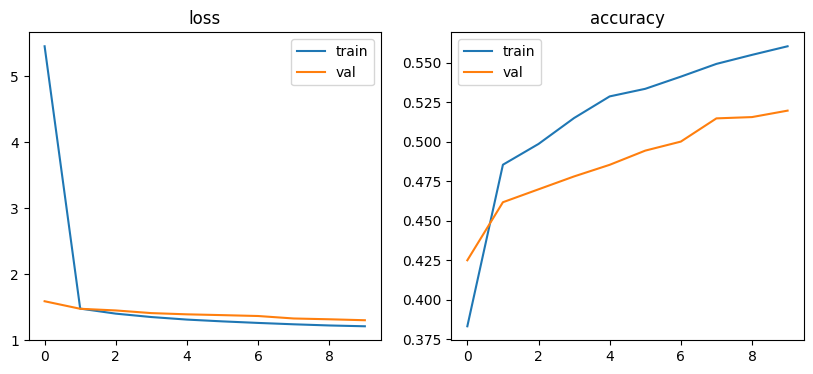

val accuracy: 0.519575834274292


In [21]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history_base.history["loss"], label="train")
plt.plot(history_base.history["val_loss"], label="val")
plt.title("loss")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_base.history["accuracy"], label="train")
plt.plot(history_base.history["val_accuracy"], label="val")
plt.title("accuracy")
plt.legend()
plt.show()

print("val accuracy:", history_base.history["val_accuracy"][-1])

La baseline atteint 52,0 % de précision sur la validation (56,0 % sur le train). C'est bien au-dessus du hasard (14 %) et de toujours prédire joie (environ 39 %). Les courbes montent encore à l'epoch 10 et l'écart train/validation reste petit (4 points) : il n'y a pas de surapprentissage, le modèle apprend simplement lentement, probablement parce que Flatten perd la position des pixels. La loss de la première epoch est très haute (5,46) : avec 30 000 entrées, les premières mises à jour sont brutales. C'est la référence à battre.

## Partie 3 : CNN avec Keras
Trois blocs Conv2D + MaxPooling, puis Flatten, Dense(128, relu) et Dense(7, softmax). Le nombre de filtres passe de 32 à 64 puis 128 : les premières couches détectent des contours, les suivantes les combinent en formes plus complexes (yeux, bouche), donc il faut plus de motifs différents. Je prends trois blocs parce que les visages ont des détails plus fins que des chiffres.

Un filtre est une petite matrice de poids (ici 3x3), apprise par rétropropagation, qui détecte un motif. Pour la convolution, il glisse sur l'image : on multiplie terme à terme la zone par le filtre et on additionne, ce qui donne une valeur de la feature map. Chaque filtre produit une feature map, donc 32 filtres donnent 32 feature maps empilées. Le filtre a la profondeur de ce qu'il reçoit : 3 sur la première couche (rouge, vert, bleu), puis celle de la couche précédente.

Le kernel fait 3x3 pour repérer des motifs locaux avec peu de paramètres. Le stride est de 1 et il n'y a pas de padding, donc chaque convolution enlève 2 pixels (n - 3 + 1). ReLU est appliqué après chaque convolution pour la non-linéarité. Le MaxPooling 2x2 garde la valeur maximale de chaque zone : il divise la hauteur et la largeur par 2, réduit les calculs et rend le modèle moins sensible à un petit décalage du visage.

Flatten met les feature maps à plat en un vecteur (aucun paramètre), car Dense attend un vecteur. Dense(128) combine les caractéristiques extraites pour décider, et la sortie Dense(7) avec softmax donne une probabilité par expression.

In [22]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

tf.keras.utils.set_random_seed(42)

cnn = Sequential([
    Input(shape=(100, 100, 3)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(7, activation="softmax"),
])
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,638,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,732,679 (6.61 MB)

 Trainable params: 1,732,679 (6.61 MB)

 Non-trainable params: 0 (0.00 B)

Dimensions et paramètres, calculés à la main (n - 3 + 1 pour une convolution 3x3, partie entière de n/2 pour le pooling) :

- Entrée : 100x100x3
- Conv2D(32) : 98x98x32, soit (3*3*3 + 1) * 32 = 896 paramètres
- MaxPooling : 49x49x32
- Conv2D(64) : 47x47x64, soit (3*3*32 + 1) * 64 = 18 496 paramètres
- MaxPooling : 23x23x64 (47 / 2 = 23 en partie entière)
- Conv2D(128) : 21x21x128, soit (3*3*64 + 1) * 128 = 73 856 paramètres
- MaxPooling : 10x10x128 (21 / 2 = 10 en partie entière)
- Flatten : 10*10*128 = 12 800
- Dense(128) : 12 800*128 + 128 = 1 638 528 paramètres
- Dense(7) : 128*7 + 7 = 903 paramètres

Total : 1 732 679 paramètres. Presque tout est dans le premier Dense : les trois convolutions n'en ont que 93 248 grâce au partage des poids.

## Partie 4 : entraînement
Perte : categorical_crossentropy, parce que les labels sont en one-hot et que la sortie est un softmax à 7 classes. Optimiseur : Adam, qui adapte le pas de chaque paramètre. Batch size de 128 : le réseau met à jour ses poids après chaque groupe de 128 images, soit 87 mises à jour par epoch, ce qui est un compromis entre vitesse et stabilité. 10 epochs, un epoch étant un passage complet sur le train. Métrique : l'accuracy, la proportion d'images bien classées (la loss sert à entraîner, l'accuracy sert à lire le résultat).

In [23]:
cnn.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

history_cnn = cnn.fit(
    x_train, y_train_oh,
    epochs=10,
    batch_size=128,
    validation_data=(x_val, y_val_oh),
)

Epoch 1/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 19s 129ms/step - accuracy: 0.4106 - loss: 1.5644 - val_accuracy: 0.5196 - val_loss: 1.2967
Epoch 2/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.6131 - loss: 1.0866 - val_accuracy: 0.6387 - val_loss: 1.0051
Epoch 3/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.6920 - loss: 0.8821 - val_accuracy: 0.6705 - val_loss: 0.9183
Epoch 4/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.7313 - loss: 0.7614 - val_accuracy: 0.6909 - val_loss: 0.8681
Epoch 5/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.7649 - loss: 0.6762 - val_accuracy: 0.7259 - val_loss: 0.8121
Epoch 6/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.7901 - loss: 0.5984 - val_accuracy: 0.7235 - val_loss: 0.7952
Epoch 7/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.8269 - loss: 0.5110 - val_accuracy: 0.7341 - val_loss: 0.8210
Epoch 8/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.8469 - loss: 0.4464 - val_accuracy: 0.6974 -

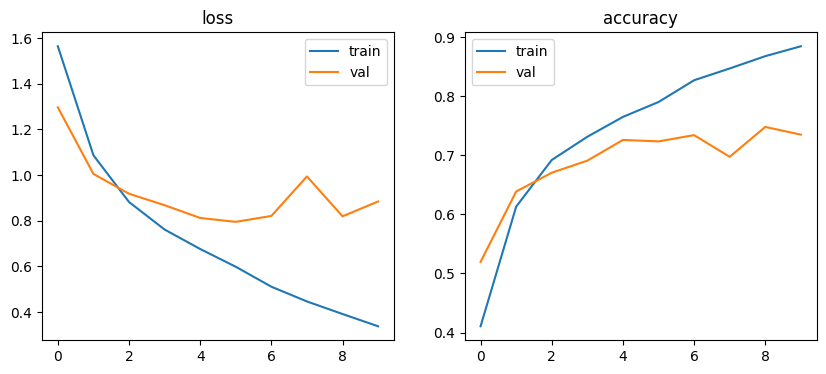

val accuracy baseline: 0.519575834274292
val accuracy CNN: 0.734910249710083


In [24]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["loss"], label="train")
plt.plot(history_cnn.history["val_loss"], label="val")
plt.title("loss")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["accuracy"], label="train")
plt.plot(history_cnn.history["val_accuracy"], label="val")
plt.title("accuracy")
plt.legend()
plt.show()

print("val accuracy baseline:", history_base.history["val_accuracy"][-1])
print("val accuracy CNN:", history_cnn.history["val_accuracy"][-1])

Le CNN atteint 73,5 % sur la validation (88,5 % sur le train), contre 52,0 % pour la baseline : plus de 21 points de plus, donc la convolution aide beaucoup.

Il y a du surapprentissage : la loss d'entraînement baisse tout le long (de 1,56 à 0,34), alors que la loss de validation est la plus basse à l'epoch 6 (0,795) puis remonte et devient instable (0,99 à l'epoch 8, 0,88 à l'epoch 10). L'écart d'accuracy entre train et validation atteint 15 points. Le modèle commence à apprendre le train par coeur, donc la partie 6 testera EarlyStopping, Dropout et la Data Augmentation.

## Partie 5 : évaluation et analyse des erreurs
L'accuracy seule ne suffit pas avec des classes déséquilibrées, donc je regarde la matrice de confusion et les résultats par classe. Je fais cette analyse sur la validation : le test est réservé à l'évaluation finale du modèle retenu.

39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step
accuracy: 0.734910277324633


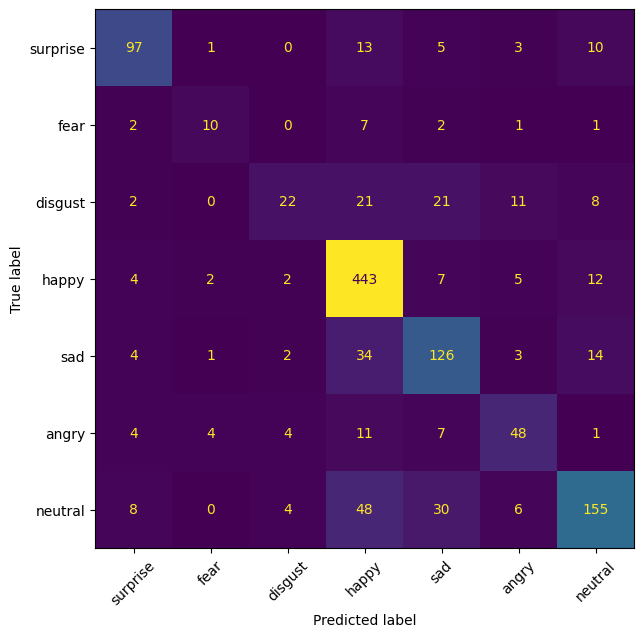

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

x_eval, y_eval = x_val, y_val

probs = cnn.predict(x_eval)
y_pred = np.argmax(probs, axis=1)
print("accuracy:", (y_pred == y_eval).mean())

cm = confusion_matrix(y_eval, y_pred)
fig, ax = plt.subplots(figsize=(7, 7))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, colorbar=False)
plt.xticks(rotation=45)
plt.show()

Dans la matrice, une ligne est la vraie classe, une colonne la classe prédite, et la diagonale contient les bonnes prédictions. Le taux de reconnaissance d'une classe est la diagonale divisée par le total de la ligne.

In [26]:
for i, c in enumerate(classes):
    print(c, cm[i, i], "/", cm[i].sum(), round(cm[i, i] / cm[i].sum(), 2))

errors_cm = cm.copy()
np.fill_diagonal(errors_cm, 0)
top = np.dstack(np.unravel_index(np.argsort(-errors_cm.ravel())[:6], errors_cm.shape))[0]
print()
for i, j in top:
    print("true", classes[i], "-> predicted", classes[j], ":", errors_cm[i, j])

surprise 97 / 129 0.75
fear 10 / 23 0.43
disgust 22 / 85 0.26
happy 443 / 475 0.93
sad 126 / 184 0.68
angry 48 / 79 0.61
neutral 155 / 251 0.62

true neutral -> predicted happy : 48
true sad -> predicted happy : 34
true neutral -> predicted sad : 30
true disgust -> predicted happy : 21
true disgust -> predicted sad : 21
true sad -> predicted neutral : 14


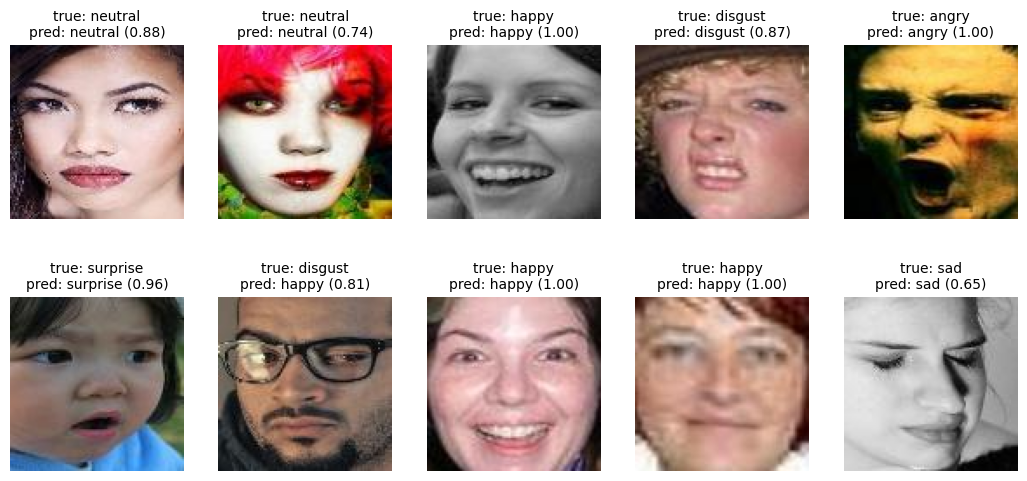

In [27]:
def show(indices):
    plt.figure(figsize=(13, 6))
    for k, i in enumerate(indices):
        plt.subplot(2, 5, k + 1)
        plt.imshow(x_eval[i])
        plt.title(f"true: {classes[y_eval[i]]}\npred: {classes[y_pred[i]]} ({probs[i].max():.2f})", fontsize=10)
        plt.axis("off")
    plt.show()

show(np.random.choice(len(x_eval), 10, replace=False))

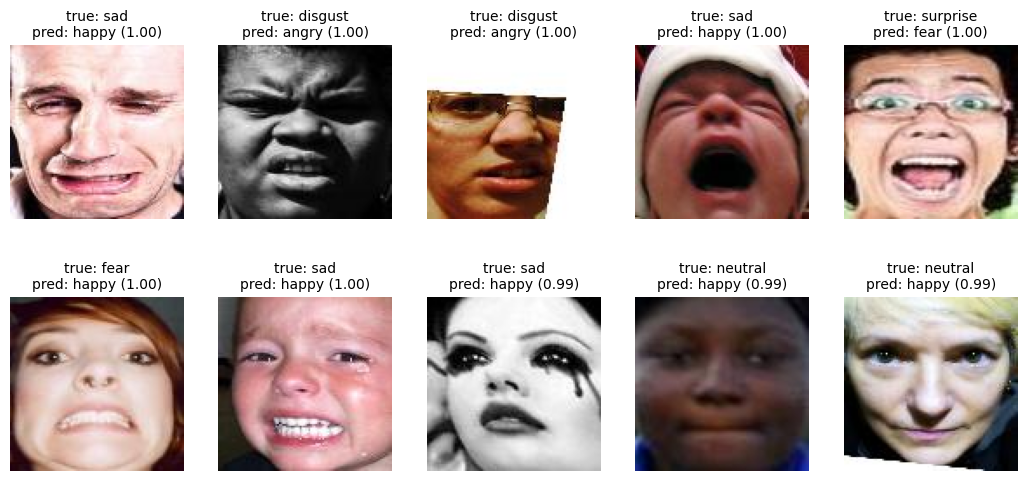

In [28]:
wrong = np.where(y_pred != y_eval)[0]
worst = wrong[np.argsort(-probs[wrong].max(axis=1))[:10]]
show(worst)

Sur la validation, l'accuracy est de 73,5 % mais elle varie beaucoup selon la classe. Joie (443 sur 475, soit 0,93) est très bien reconnue, puis surprise (0,75) et tristesse (0,68). Neutre et colère sont autour de 0,6. Peur (0,43) et dégoût (0,26) sont les plus mal reconnues. Peur est la classe la plus rare (281 images d'entraînement) et il n'y en a que 23 dans la validation, donc son taux est peu fiable. Dégoût a autant d'images que colère (717 contre 704) mais il est bien moins reconnu (0,26 contre 0,61) : ce n'est pas seulement un problème d'effectif, l'expression est plus subtile et ressemble à d'autres.

Les confusions les plus fréquentes sont neutre pris pour joie (48), tristesse prise pour joie (34) et neutre pris pour tristesse (30). Dégoût est pris pour joie (21) ou pour tristesse (21) dans la moitié des cas. Joie sert un peu de classe par défaut : c'est la plus grosse classe (39 % du train), donc le modèle la prédit quand il hésite.

Sur les erreurs où le modèle est le plus sûr de lui (100 %), ce sont de vraies erreurs et pas des étiquettes discutables : des visages qui pleurent la bouche ouverte sont prédits joie, donc le modèle s'appuie beaucoup sur la bouche ouverte et les dents. On voit aussi dégoût prédit colère et surprise prédite peur, deux paires d'expressions proches.

## Partie 6 : expériences
Je pars du CNN de la partie 4 et je change une seule chose à la fois. Je compare sur la validation, et chaque entraînement dure au maximum 30 epochs avec EarlyStopping : on arrête quand la loss de validation ne baisse plus pendant 3 epochs et on garde les meilleurs poids. Je suis aussi dégoût et peur à part, parce que l'accuracy seule cache les classes difficiles.

In [29]:
from tensorflow.keras.layers import Dropout, RandomFlip, RandomRotation, RandomZoom
from tensorflow.keras.callbacks import EarlyStopping

def build_cnn(filters=(32, 64, 128), dropout=0.0, augment=False):
    tf.keras.utils.set_random_seed(42)
    model = Sequential([Input(shape=(100, 100, 3))])
    if augment:
        model.add(RandomFlip("horizontal"))
        model.add(RandomRotation(0.05))
        model.add(RandomZoom(0.1))
    for f in filters:
        model.add(Conv2D(f, (3, 3), activation="relu"))
        model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Flatten())
    model.add(Dense(128, activation="relu"))
    if dropout > 0:
        model.add(Dropout(dropout))
    model.add(Dense(7, activation="softmax"))
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model

results = {}
histories = {}

def report(name, model, epoch):
    loss, acc = model.evaluate(x_val, y_val_oh, verbose=0)
    pred = np.argmax(model.predict(x_val, verbose=0), axis=1)
    recall = [(pred[y_val == i] == i).mean() for i in range(7)]
    results[name] = dict(epoch=epoch, loss=loss, acc=acc,
                         disgust=recall[classes.index("disgust")],
                         fear=recall[classes.index("fear")])

def run(name, model):
    stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    h = model.fit(x_train, y_train_oh, epochs=30, batch_size=128,
                  validation_data=(x_val, y_val_oh), callbacks=[stop], verbose=2)
    histories[name] = h.history
    report(name, model, int(np.argmin(h.history["val_loss"])) + 1)

report("0 partie 4 (10 epochs)", cnn, 10)
histories["0 partie 4 (10 epochs)"] = history_cnn.history

### Expérience 1 : EarlyStopping
Le même CNN qu'en partie 4, mais on s'arrête à la meilleure epoch au lieu de forcer 10 epochs.

In [30]:
run("1 earlystopping", build_cnn())

Epoch 1/30
87/87 - 10s - 120ms/step - accuracy: 0.4099 - loss: 1.5643 - val_accuracy: 0.5073 - val_loss: 1.2936
Epoch 2/30
87/87 - 4s - 47ms/step - accuracy: 0.6104 - loss: 1.0915 - val_accuracy: 0.6444 - val_loss: 0.9919
Epoch 3/30
87/87 - 4s - 47ms/step - accuracy: 0.6867 - loss: 0.8827 - val_accuracy: 0.6648 - val_loss: 0.9336
Epoch 4/30
87/87 - 4s - 47ms/step - accuracy: 0.7303 - loss: 0.7629 - val_accuracy: 0.6778 - val_loss: 0.8760
Epoch 5/30
87/87 - 4s - 48ms/step - accuracy: 0.7601 - loss: 0.6841 - val_accuracy: 0.6998 - val_loss: 0.8199
Epoch 6/30
87/87 - 4s - 48ms/step - accuracy: 0.7925 - loss: 0.5968 - val_accuracy: 0.7243 - val_loss: 0.8137
Epoch 7/30
87/87 - 4s - 48ms/step - accuracy: 0.8233 - loss: 0.5099 - val_accuracy: 0.7235 - val_loss: 0.7948
Epoch 8/30
87/87 - 4s - 47ms/step - accuracy: 0.8469 - loss: 0.4454 - val_accuracy: 0.7406 - val_loss: 0.7977
Epoch 9/30
87/87 - 4s - 49ms/step - accuracy: 0.8633 - loss: 0.3942 - val_accuracy: 0.7251 - val_loss: 0.9171
Epoch 10

L'entraînement s'arrête après 10 epochs et garde la 7 : 72,3 % en validation (contre 73,5 %) et une loss de 0,795 (contre 0,884). La loss est meilleure et l'accuracy un peu plus basse, ce qui est dans le bruit. Le surapprentissage est toujours là : à l'epoch 7, 82 % sur le train contre 72 % sur la validation.

### Expérience 2 : Dropout
J'ajoute Dropout(0.5) après Dense(128). À chaque batch, la moitié des neurones de cette couche est éteinte au hasard, donc le réseau ne peut pas compter sur quelques neurones et apprend moins par coeur.

In [31]:
run("2 dropout 0.5", build_cnn(dropout=0.5))

Epoch 1/30
87/87 - 11s - 128ms/step - accuracy: 0.4042 - loss: 1.6057 - val_accuracy: 0.5073 - val_loss: 1.3272
Epoch 2/30
87/87 - 4s - 47ms/step - accuracy: 0.5506 - loss: 1.2407 - val_accuracy: 0.6207 - val_loss: 1.0522
Epoch 3/30
87/87 - 4s - 47ms/step - accuracy: 0.6194 - loss: 1.0697 - val_accuracy: 0.6574 - val_loss: 0.9627
Epoch 4/30
87/87 - 4s - 47ms/step - accuracy: 0.6658 - loss: 0.9606 - val_accuracy: 0.6933 - val_loss: 0.8930
Epoch 5/30
87/87 - 4s - 47ms/step - accuracy: 0.6843 - loss: 0.8825 - val_accuracy: 0.7113 - val_loss: 0.8420
Epoch 6/30
87/87 - 4s - 47ms/step - accuracy: 0.7173 - loss: 0.7993 - val_accuracy: 0.7243 - val_loss: 0.8039
Epoch 7/30
87/87 - 4s - 48ms/step - accuracy: 0.7421 - loss: 0.7253 - val_accuracy: 0.7390 - val_loss: 0.7915
Epoch 8/30
87/87 - 4s - 47ms/step - accuracy: 0.7570 - loss: 0.6833 - val_accuracy: 0.7382 - val_loss: 0.7780
Epoch 9/30
87/87 - 4s - 48ms/step - accuracy: 0.7735 - loss: 0.6380 - val_accuracy: 0.7414 - val_loss: 0.7373
Epoch 10

L'entraînement s'arrête après 12 epochs et garde la 9 : 74,1 % en validation et une loss de 0,737, le meilleur résultat des expériences. L'écart entre train et validation est plus petit (77 % contre 74 % à l'epoch 9), donc Dropout freine bien le surapprentissage.

### Expérience 3 : Data Augmentation
J'ajoute en entrée du réseau des transformations aléatoires : retournement horizontal, rotation (environ 18 degrés au plus) et zoom de 10 %. Un visage retourné garde la même expression, donc le label ne change pas. Ces transformations ne s'appliquent que pendant l'entraînement.

In [32]:
run("3 augmentation", build_cnn(augment=True))

Epoch 1/30
87/87 - 12s - 136ms/step - accuracy: 0.4185 - loss: 1.5537 - val_accuracy: 0.4821 - val_loss: 1.3227
Epoch 2/30
87/87 - 4s - 45ms/step - accuracy: 0.5385 - loss: 1.2658 - val_accuracy: 0.5922 - val_loss: 1.1025
Epoch 3/30
87/87 - 4s - 45ms/step - accuracy: 0.5930 - loss: 1.1268 - val_accuracy: 0.6240 - val_loss: 1.0218
Epoch 4/30
87/87 - 4s - 46ms/step - accuracy: 0.6333 - loss: 1.0229 - val_accuracy: 0.6452 - val_loss: 0.9761
Epoch 5/30
87/87 - 5s - 58ms/step - accuracy: 0.6627 - loss: 0.9502 - val_accuracy: 0.6664 - val_loss: 0.9122
Epoch 6/30
87/87 - 4s - 46ms/step - accuracy: 0.6826 - loss: 0.8994 - val_accuracy: 0.6794 - val_loss: 0.8835
Epoch 7/30
87/87 - 4s - 46ms/step - accuracy: 0.6953 - loss: 0.8570 - val_accuracy: 0.7088 - val_loss: 0.8117
Epoch 8/30
87/87 - 4s - 46ms/step - accuracy: 0.7073 - loss: 0.8146 - val_accuracy: 0.6876 - val_loss: 0.8776
Epoch 9/30
87/87 - 4s - 46ms/step - accuracy: 0.7144 - loss: 0.7957 - val_accuracy: 0.7015 - val_loss: 0.8228
Epoch 10

La meilleure epoch est la 7, avec 70,9 % en validation et une loss de 0,812 : c'est moins bien que les autres expériences. L'écart entre train et validation a disparu (69,5 % contre 70,9 % à l'epoch 7), donc il n'y a plus de surapprentissage, mais le réseau apprend plus lentement parce que les images changent à chaque epoch. La loss de validation oscille (de 0,81 à 0,88) et EarlyStopping arrête à l'epoch 10, peut-être un peu tôt.

### Expérience 4 : Dropout et Data Augmentation ensemble
Les deux ont réduit le surapprentissage, donc je les combine.

In [33]:
model4 = build_cnn(dropout=0.5, augment=True)
run("4 dropout + augmentation", model4)

Epoch 1/30
87/87 - 6s - 72ms/step - accuracy: 0.3973 - loss: 1.6234 - val_accuracy: 0.4535 - val_loss: 1.4312
Epoch 2/30
87/87 - 4s - 46ms/step - accuracy: 0.4688 - loss: 1.4359 - val_accuracy: 0.5530 - val_loss: 1.2520
Epoch 3/30
87/87 - 4s - 45ms/step - accuracy: 0.5271 - loss: 1.3055 - val_accuracy: 0.5840 - val_loss: 1.1350
Epoch 4/30
87/87 - 4s - 46ms/step - accuracy: 0.5556 - loss: 1.2239 - val_accuracy: 0.6183 - val_loss: 1.0585
Epoch 5/30
87/87 - 4s - 46ms/step - accuracy: 0.5755 - loss: 1.1601 - val_accuracy: 0.6183 - val_loss: 1.0182
Epoch 6/30
87/87 - 4s - 46ms/step - accuracy: 0.6026 - loss: 1.0992 - val_accuracy: 0.6558 - val_loss: 0.9501
Epoch 7/30
87/87 - 4s - 46ms/step - accuracy: 0.6154 - loss: 1.0576 - val_accuracy: 0.6705 - val_loss: 0.9190
Epoch 8/30
87/87 - 4s - 46ms/step - accuracy: 0.6330 - loss: 1.0247 - val_accuracy: 0.6827 - val_loss: 0.8815
Epoch 9/30
87/87 - 5s - 59ms/step - accuracy: 0.6365 - loss: 1.0054 - val_accuracy: 0.6860 - val_loss: 0.8897
Epoch 10/3

La meilleure epoch est la 19, avec 72,8 % en validation et une loss de 0,755, entre les deux techniques seules. Il faut beaucoup plus d'epochs (19 contre 9 pour Dropout) parce que les deux régularisations ralentissent l'apprentissage, et ça ne fait pas mieux : elles agissent sur le même problème, le surapprentissage, donc elles ne s'additionnent pas ici. L'accuracy d'entraînement est plus basse que celle de validation (71 % contre 73 %), c'est normal parce que Dropout et augmentation ne sont actifs que pendant l'entraînement.

### Comparaison

experience                 epoch  val acc  val loss  disgust   fear
0 partie 4 (10 epochs)        10    0.735     0.884     0.26   0.43
1 earlystopping                7    0.723     0.795     0.24   0.43
2 dropout 0.5                  9    0.741     0.737     0.40   0.39
3 augmentation                 7    0.709     0.812     0.38   0.30
4 dropout + augmentation      19    0.728     0.755     0.18   0.35


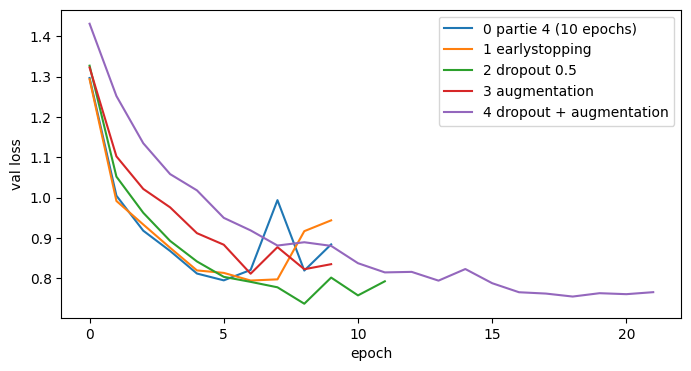

In [34]:
print(f"{'experience':<26}{'epoch':>6}{'val acc':>9}{'val loss':>10}{'disgust':>9}{'fear':>7}")
for name, r in results.items():
    print(f"{name:<26}{r['epoch']:>6}{r['acc']:>9.3f}{r['loss']:>10.3f}{r['disgust']:>9.2f}{r['fear']:>7.2f}")

plt.figure(figsize=(8, 4))
for name, h in histories.items():
    plt.plot(h["val_loss"], label=name)
plt.xlabel("epoch")
plt.ylabel("val loss")
plt.legend()
plt.show()

Toutes les expériences sont entre 71 % et 74 % en validation, donc proches de la partie 4 (73,5 %). Dropout est le meilleur sur les deux critères (74,1 % et loss 0,737). EarlyStopping et la combinaison gagnent surtout sur la loss, et l'augmentation seule fait moins bien (70,9 %). Les écarts restent petits : un point représente environ 12 images sur les 1 226 de la validation, donc on ne peut pas conclure sur moins de 2 points. Dégoût et peur bougent beaucoup d'une expérience à l'autre (dégoût de 0,18 à 0,40, peur de 0,30 à 0,43), parce qu'il y a seulement 85 et 23 images de ces classes en validation.

### Modèle final
Je retiens Dropout(0.5) seul : c'est le meilleur en accuracy et en loss de validation, avec le meilleur taux sur dégoût, et c'est le plus simple des modèles qui améliorent la partie 4. Je le ré-entraîne pour garder le modèle dans une variable, puis j'utilise le test une seule fois.

In [42]:
final_model = build_cnn(dropout=0.5)
run("final : dropout", final_model)

Epoch 1/30
87/87 - 11s - 129ms/step - accuracy: 0.4070 - loss: 1.6042 - val_accuracy: 0.5082 - val_loss: 1.3318
Epoch 2/30
87/87 - 4s - 48ms/step - accuracy: 0.5463 - loss: 1.2392 - val_accuracy: 0.6077 - val_loss: 1.0730
Epoch 3/30
87/87 - 4s - 47ms/step - accuracy: 0.6201 - loss: 1.0667 - val_accuracy: 0.6533 - val_loss: 0.9590
Epoch 4/30
87/87 - 4s - 48ms/step - accuracy: 0.6601 - loss: 0.9654 - val_accuracy: 0.6876 - val_loss: 0.8973
Epoch 5/30
87/87 - 4s - 47ms/step - accuracy: 0.6840 - loss: 0.8833 - val_accuracy: 0.7039 - val_loss: 0.8497
Epoch 6/30
87/87 - 4s - 47ms/step - accuracy: 0.7135 - loss: 0.7997 - val_accuracy: 0.7088 - val_loss: 0.8249
Epoch 7/30
87/87 - 4s - 47ms/step - accuracy: 0.7352 - loss: 0.7404 - val_accuracy: 0.7284 - val_loss: 0.7764
Epoch 8/30
87/87 - 4s - 47ms/step - accuracy: 0.7575 - loss: 0.6826 - val_accuracy: 0.7357 - val_loss: 0.7988
Epoch 9/30
87/87 - 4s - 47ms/step - accuracy: 0.7728 - loss: 0.6372 - val_accuracy: 0.7480 - val_loss: 0.7751
Epoch 10

Le ré-entraînement garde la 9, comme l'expérience 2 : 74,8 % en validation et une loss de 0,775 (contre 74,1 % et 0,737). La même configuration donne un résultat un peu différent d'une exécution à l'autre, de moins d'un point sur l'accuracy et de 0,04 sur la loss, donc des écarts de cet ordre entre expériences ne veulent rien dire.

## Évaluation finale sur le test

test loss: 0.7317459583282471
test accuracy: 0.7489403486251831
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


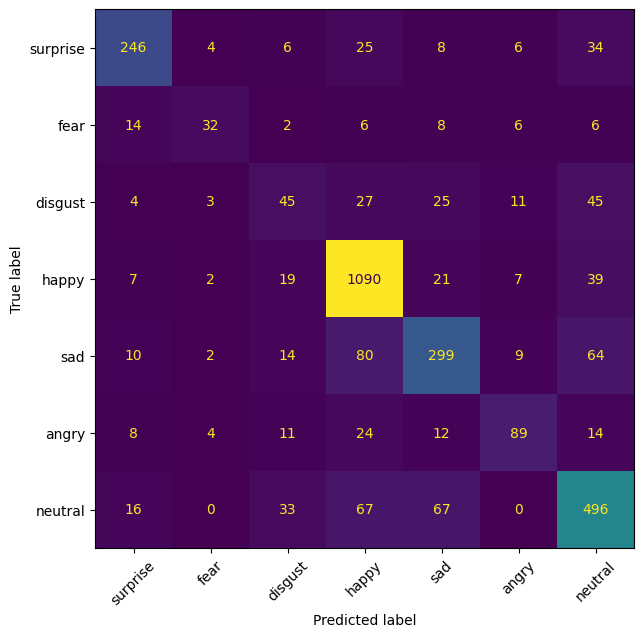

surprise 246 / 329 0.75
fear 32 / 74 0.43
disgust 45 / 160 0.28
happy 1090 / 1185 0.92
sad 299 / 478 0.63
angry 89 / 162 0.55
neutral 496 / 679 0.73


In [43]:
test_loss, test_acc = final_model.evaluate(x_test, y_test_oh, verbose=0)
print("test loss:", test_loss)
print("test accuracy:", test_acc)

pred_test = np.argmax(final_model.predict(x_test), axis=1)
cm_test = confusion_matrix(y_test, pred_test)

fig, ax = plt.subplots(figsize=(7, 7))
ConfusionMatrixDisplay(cm_test, display_labels=classes).plot(ax=ax, colorbar=False)
plt.xticks(rotation=45)
plt.show()

for i, c in enumerate(classes):
    print(c, cm_test[i, i], "/", cm_test[i].sum(), round(cm_test[i, i] / cm_test[i].sum(), 2))

final_model.save("expressions_cnn.keras")

Sur le test, l'accuracy est de 74,9 % (loss 0,732), cohérente avec la validation (74,8 %) : le modèle généralise comme prévu. Le hasard donnerait 14 % et toujours prédire joie environ 39 %.

Par classe : joie 0,92, surprise 0,75, neutre 0,73, tristesse 0,63, colère 0,55, peur 0,43, dégoût 0,28 (45 sur 160). Dégoût est autant pris pour neutre (45) que reconnu, puis pour joie (27) et tristesse (25). Les confusions les plus fréquentes sont tristesse prise pour joie (80), neutre pris pour joie (67) et pour tristesse (67), et tristesse prise pour neutre (64). Ce sont les mêmes qu'en validation : joie, neutre et tristesse se mélangent.

## Partie 7 : enrichissement
J'ai utilisé la Data Augmentation, Dropout et EarlyStopping contre le surapprentissage, et la détection d'objets avec YOLO pour traiter des images à plusieurs visages (parties 8 et 9). Je n'ai pas fait de transfer learning : le détecteur de visages est un YOLO déjà entraîné que j'utilise tel quel, sans fine-tuning, et le CNN d'expressions est entraîné de zéro.

## Partie 8 : détection de plusieurs visages
Jusqu'ici le CNN reçoit un visage déjà découpé. Ici, YOLO trouve les visages dans l'image, je découpe chaque boîte et je la passe au CNN. Ce sont deux modèles avec deux rôles : YOLO dit où sont les visages, le CNN dit quelle expression a chacun.

Un YOLO standard (COCO) détecte des personnes mais pas des visages. J'utilise donc `arnabdhar/YOLOv8-Face-Detection` sur Hugging Face, un YOLOv8 déjà entraîné sur des visages (licence AGPL-3.0 d'après la page du modèle), sans le ré-entraîner.

In [44]:
%pip install -q ultralytics huggingface_hub

In [45]:
import cv2
from huggingface_hub import hf_hub_download
from ultralytics import YOLO

detector = YOLO(hf_hub_download("arnabdhar/YOLOv8-Face-Detection", "model.pt"))

Photo de test avec plusieurs visages : `group.jpeg`.

In [46]:
img = cv2.imread("/content/group.jpeg")

result = detector(img, conf=0.4, verbose=False)[0]
boxes = result.boxes.xyxy.cpu().numpy().astype(int)
scores = result.boxes.conf.cpu().numpy()
print(len(boxes), "visages détectés")

8 visages détectés


Chaque visage détecté est découpé puis passe par le même prétraitement qu'en partie 1 (couleur RVB, 100x100, divisé par 255), sinon les prédictions n'ont pas de sens.

happy [          0           0        0.03        0.94        0.02           0        0.01] score détection: 0.94
happy [          0           0           0           1           0           0           0] score détection: 0.91
happy [          0           0        0.03        0.95        0.01           0           0] score détection: 0.89
happy [          0           0        0.03        0.93        0.02        0.01           0] score détection: 0.88
happy [          0           0           0           1           0           0           0] score détection: 0.87
happy [          0        0.01        0.05        0.88        0.04        0.02           0] score détection: 0.87
happy [       0.01        0.01        0.08         0.8        0.04        0.01        0.05] score détection: 0.86
happy [       0.02        0.02        0.03        0.68        0.14           0        0.12] score détection: 0.82


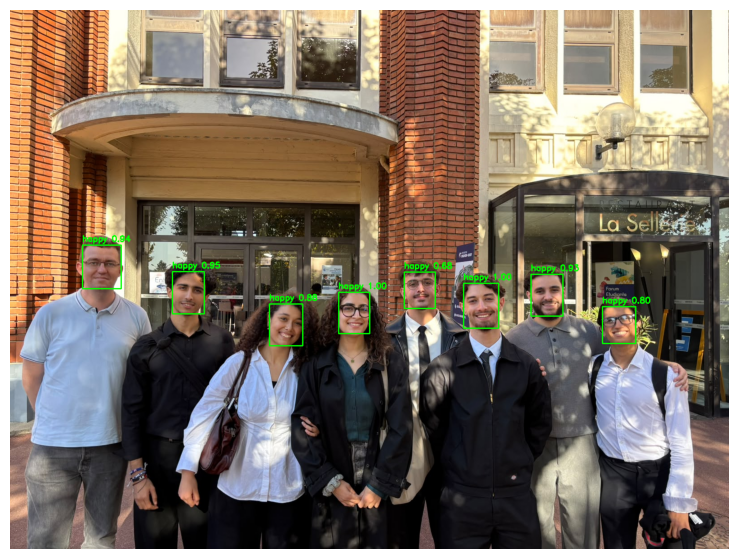

In [47]:
img_out = img.copy()
for (x1, y1, x2, y2), s in zip(boxes, scores):
    face = cv2.cvtColor(img[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)
    face = cv2.resize(face, (100, 100)).astype("float32") / 255
    p = final_model.predict(face.reshape(1, 100, 100, 3), verbose=0)[0]
    k = p.argmax()
    cv2.rectangle(img_out, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(img_out, f"{classes[k]} {p[k]:.2f}", (x1, max(y1 - 8, 15)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    print(classes[k], p.round(2), "score détection:", round(float(s), 2))

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(img_out, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## Partie 9 : vidéo en direct
Pour la démonstration, j'ai fait un petit script (`webcam.py`) qui applique la même chaîne que la partie 8 à chaque image de la webcam. Chaque visage est suivi d'une image à l'autre avec l'IoU : la boîte qui chevauche le plus celle de l'image précédente garde le même numéro. Je fais la moyenne des probabilités sur les 10 dernières images pour que l'expression ne clignote pas. Chaque expression a sa couleur, comme les personnages de Vice-Versa.